In [4]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"C:\projects\smart-community\data\harmful-contents")

train = pd.read_csv(DATA_DIR / "csv" / "train.csv")
print(train.shape)
print(train.columns.tolist())
print(train.head())

(3609, 17)
['name', 'alcohol', 'drugs', 'weapons', 'gambling', 'nudity', 'sexy', 'smoking', 'violence', 'mask_alcohol', 'mask_drugs', 'mask_weapons', 'mask_gambling', 'mask_nudity', 'mask_sexy', 'mask_smoking', 'mask_violence']
    name  alcohol  drugs  weapons  gambling  nudity  sexy  smoking  violence  \
0  1.jpg        0      0        1         0       0     0        0         1   
1  2.jpg        0      0        0         0       0     0        0         0   
2  6.jpg        0      0        0         0       0     0        0         0   
3  7.jpg        0      0        0         0       0     0        0         0   
4  8.jpg        0      0        0         0       0     0        0         0   

   mask_alcohol  mask_drugs  mask_weapons  mask_gambling  mask_nudity  \
0             0           0             1              0            0   
1             0           0             1              0            0   
2             0           1             0              0            0   

In [5]:
print(train.info())
print(train.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3609 entries, 0 to 3608
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           3609 non-null   object
 1   alcohol        3609 non-null   int64 
 2   drugs          3609 non-null   int64 
 3   weapons        3609 non-null   int64 
 4   gambling       3609 non-null   int64 
 5   nudity         3609 non-null   int64 
 6   sexy           3609 non-null   int64 
 7   smoking        3609 non-null   int64 
 8   violence       3609 non-null   int64 
 9   mask_alcohol   3609 non-null   int64 
 10  mask_drugs     3609 non-null   int64 
 11  mask_weapons   3609 non-null   int64 
 12  mask_gambling  3609 non-null   int64 
 13  mask_nudity    3609 non-null   int64 
 14  mask_sexy      3609 non-null   int64 
 15  mask_smoking   3609 non-null   int64 
 16  mask_violence  3609 non-null   int64 
dtypes: int64(16), object(1)
memory usage: 479.4+ KB
None
name             0

In [6]:
cat_cols = ["alcohol", "drugs", "weapons", "gambling",
            "nudity", "sexy", "smoking", "violence"]

# How many images have each flag set
print(train[cat_cols].sum())

# Check the values in each column
for c in cat_cols:
    print(c, train[c].unique())

alcohol     213
drugs       177
weapons     417
gambling    217
nudity      361
sexy        461
smoking     357
violence    481
dtype: int64
alcohol [0 1]
drugs [0 1]
weapons [1 0]
gambling [0 1]
nudity [0 1]
sexy [0 1]
smoking [0 1]
violence [1 0]


In [7]:
train["unsafe"] = (train[cat_cols].sum(axis=1) > 0).astype(int)
print(train["unsafe"].value_counts())

unsafe
1    1900
0    1709
Name: count, dtype: int64


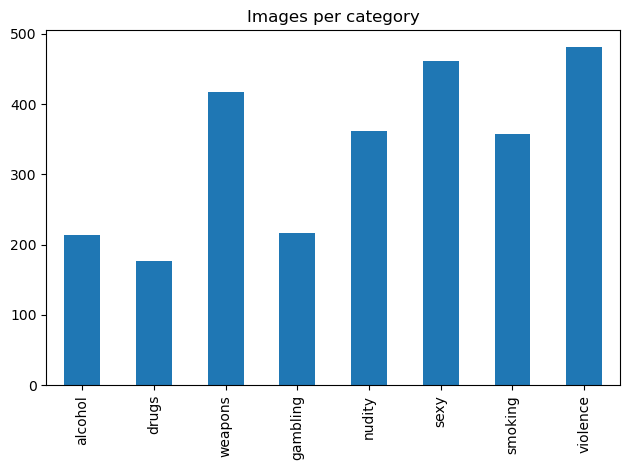

In [8]:
import matplotlib.pyplot as plt

train[cat_cols].sum().plot(kind="bar")
plt.title("Images per category")
plt.tight_layout()
plt.savefig("class_counts.png")
plt.show()

In [9]:
# 1. How many flags per image?
print(train[cat_cols].sum(axis=1).value_counts().sort_index())

# 2. Do the image files exist? (find the images folder first)
for p in sorted(DATA_DIR.iterdir()):
    print(p.name)

0    1709
1    1116
2     784
Name: count, dtype: int64
.cache
.gitattributes
csv
data
README.md


The left number is the number of flags an image has. The right number is how many images have that many flags.

0 flags: 1,709 images. Nothing harmful flagged, so these are your safe images.
1 flag: 1,116 images. One category flagged (for example, only weapons).
2 flags: 784 images. Two categories flagged together (for example, weapons and violence).
No image has 3 or more flags.

In [10]:
DATA_DIR = Path(r"C:\projects\smart-community\data\harmful-contents")
cat_cols = ["alcohol", "drugs", "weapons", "gambling",
            "nudity", "sexy", "smoking", "violence"]

# 1. Load every CSV file (train, val, test)
splits = {}
for f in sorted((DATA_DIR / "csv").glob("*.csv")):
    df = pd.read_csv(f)
    df["unsafe"] = (df[cat_cols].sum(axis=1) > 0).astype(int)
    splits[f.stem] = df
    print(f.name, df.shape)
    print(df["unsafe"].value_counts().to_dict())


test.csv (773, 18)
{1: 409, 0: 364}
train.csv (3609, 18)
{1: 1900, 0: 1709}
val.csv (771, 18)
{1: 402, 0: 369}


In [11]:
# 2. Find all image files inside the data folder
files = {p.name: p for p in (DATA_DIR / "data").rglob("*") if p.is_file()}
print("Files found in data folder:", len(files))
print("Example paths:", [str(p.relative_to(DATA_DIR)) for p in list(files.values())[:3]])


Files found in data folder: 5153
Example paths: ['data\\test\\10.jpg', 'data\\test\\1013.jpg', 'data\\test\\1016.jpg']


In [12]:
# 3. Do the CSV names match real files?
for name, df in splits.items():
    found = df["name"].isin(files.keys())
    print(name, "found:", found.sum(), "missing:", (~found).sum())


test found: 773 missing: 0
train found: 3609 missing: 0
val found: 771 missing: 0


In [13]:
# 4. Do any images appear in more than one split?
names = list(splits)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        shared = set(splits[names[i]]["name"]) & set(splits[names[j]]["name"])
        print(names[i], "&", names[j], "shared:", len(shared))


test & train shared: 0
test & val shared: 0
train & val shared: 0


In [14]:
# 5. README
print((DATA_DIR / "README.md").read_text(encoding="utf-8")[:5000])

---
pretty_name: harmful-contents
tags:
  - image-classification
  - multi-label-classification
  - computer-vision
  - content-moderation
task_categories:
  - image-classification
language:
  - en
size_categories:
  - 1K<n<10K
annotations_creators:
  - expert-generated
source_datasets:
  - original
license: other
license_name: research-and-non-commercial-use
license_link: https://huggingface.co/datasets/onullusoy/harmful-contents
---

# Harmful-Contents Dataset

A multi-label image dataset for harmful-content classification across eight PEGI-aligned categories.  
The dataset consists of 5,153 rights-cleared images, split into train/validation/test sets and annotated with both binary labels and mask fields for controlled negative sampling.

---

## Dataset Structure

```
Harmful-Contents/
  csv/
    train.csv
    val.csv
    test.csv
  data/
    train/*.jpg
    val/*.jpg
    test/*.jpg
```

Each CSV contains:

```
name,
alcohol,drugs,weapons,gambling,nudity,sexy,smoking,violence,
mask_